## Set up the notebook and look at the data before testing anything.

- H1: Are EU-banned chemicals removed more often?
- H0 (null hypothesis): The share of removed chemical entries is the same for EU-banned chemicals and for all other chemicals.
- H1 (alternative): The shares differ.
- Test: chi-square test of independence (two categories × two categories), significance level α = 0.05, plus effect sizes (odds ratio, Cramér’s V).
- Data choices: titanium dioxide is excluded (87% of products, it would dominate). Rows without a CAS number are excluded too, because for them the EU status is unknown and they would wrongly count as “not banned”.

## Step 1: 

- Load the data for the test and look at the two tables first. Table 1 counts every report row. Table 2 counts each product-chemical pair once, because a product can have many rows for the same chemical (one per shade), so rows are not independent. If both tables show the same picture, the result is robust.

In [1]:
import os                                            # read environment variables
import numpy as np                                   # numbers
import pandas as pd                                  # tables
import matplotlib.pyplot as plt                      # charts
from scipy import stats                              # statistical tests
from dotenv import load_dotenv                       # reads the .env file with the secrets
from sqlalchemy import create_engine, text          # connection + raw SQL

load_dotenv("../.env", override=True)                # .env sits one level above notebook/
engine = create_engine(os.getenv("CON_STRING"))      # connection to behind_the_label

def q(sql):
    """Run a SQL text and return the result as a table."""
    return pd.read_sql(text(sql), engine)

# 1. Data for the test: no TiO2, only rows with a known CAS number
df = q("""SELECT r.cdph_id, r.cas_id, r.cas_number, r.eu_banned, r.is_removed
          FROM reports r JOIN chemicals ch ON ch.cas_id = r.cas_id
          WHERE ch.is_tio2 = 0 AND r.cas_number IS NOT NULL""")
print("rows:", len(df))

# 2. Table 1: every report row (counts and share removed)
t1 = pd.crosstab(df["eu_banned"], df["is_removed"])                  # rows = banned (0/1), columns = removed (0/1)
t1.index = ["not banned", "banned"]
t1.columns = ["kept", "removed"]
t1["removed %"] = (100 * t1["removed"] / (t1["kept"] + t1["removed"])).round(1)
print("\nTable 1: report rows")
print(t1)

# 3. Table 2: each product-chemical pair once (removed if any of its rows was removed)
pairs = df.groupby(["cdph_id", "cas_id"], as_index=False).agg(
    eu_banned=("eu_banned", "max"), is_removed=("is_removed", "max"))
t2 = pd.crosstab(pairs["eu_banned"], pairs["is_removed"])
t2.index = ["not banned", "banned"]
t2.columns = ["kept", "removed"]
t2["removed %"] = (100 * t2["removed"] / (t2["kept"] + t2["removed"])).round(1)
print("\nTable 2: product-chemical pairs")
print(t2)

rows: 14183

Table 1: report rows
             kept  removed  removed %
not banned  12545      793        5.9
banned        704      141       16.7

Table 2: product-chemical pairs
            kept  removed  removed %
not banned  5216      513        9.0
banned       461       98       17.5


## Step 2: the chi-square test and effect sizes

- A chi-square test asks whether the difference could be due to chance. The p-value alone is not enough, because with thousands of rows tiny differences become “significant”. So I add two effect sizes: the odds ratio (how many times higher are the odds of removal for banned chemicals, with a 95% confidence interval) and Cramér’s V (0 = no association, 1 = perfect association). I run the test on both tables as a robustness check.

In [2]:
def h1_test(table, label):
    """Chi-square test + effect sizes for a 2x2 table (rows: not banned / banned, columns: kept / removed)."""
    obs = table[["kept", "removed"]].values                      # the four counts as a 2x2 array
    chi2, p, dof, expected = stats.chi2_contingency(obs, correction=False)   # test of independence
    n = obs.sum()                                                # total number of rows or pairs
    cramers_v = np.sqrt(chi2 / n)                                # effect size for a 2x2 table (0 to 1)

    a, b = obs[1, 1], obs[1, 0]                                  # banned: removed, kept
    c, d = obs[0, 1], obs[0, 0]                                  # not banned: removed, kept
    odds_ratio = (a * d) / (b * c)                               # odds of removal: banned vs not banned
    se = np.sqrt(1/a + 1/b + 1/c + 1/d)                          # standard error of log(odds ratio)
    ci_low, ci_high = np.exp(np.log(odds_ratio) + np.array([-1.96, 1.96]) * se)   # 95% confidence interval

    diff = 100 * (a / (a + b) - c / (c + d))                     # difference in removal share, percentage points
    print(f"--- {label} ---")
    print(f"chi-square = {chi2:.1f}, df = {dof}, p = {p:.2e}")
    print(f"smallest expected count = {expected.min():.0f}  (must be at least 5)")
    print(f"difference = {diff:.1f} percentage points")
    print(f"odds ratio = {odds_ratio:.2f}  (95% CI {ci_low:.2f} to {ci_high:.2f})")
    print(f"Cramer's V = {cramers_v:.3f}")
    return {"label": label, "chi2": chi2, "p": p, "diff_pp": diff, "odds_ratio": odds_ratio,
            "ci_low": ci_low, "ci_high": ci_high, "cramers_v": cramers_v}

res1 = h1_test(t1, "Table 1: report rows")
res2 = h1_test(t2, "Table 2: product-chemical pairs")

--- Table 1: report rows ---
chi-square = 149.0, df = 1, p = 2.83e-34
smallest expected count = 56  (must be at least 5)
difference = 10.7 percentage points
odds ratio = 3.17  (95% CI 2.61 to 3.85)
Cramer's V = 0.103
--- Table 2: product-chemical pairs ---
chi-square = 42.7, df = 1, p = 6.36e-11
smallest expected count = 54  (must be at least 5)
difference = 8.6 percentage points
odds ratio = 2.16  (95% CI 1.71 to 2.74)
Cramer's V = 0.082


## Step 3: robustness checks

 - Does the result depend on a few special cases? Check A: all product-chemical pairs (as before). Check B: only pairs first reported from 2011 on, to exclude the initial reporting wave of 2009-2010. Check C: without the 5 companies that have the most banned pairs, to see whether a few companies drive the result. If the odds ratio stays clearly above 1 in all checks, the finding is robust.

In [3]:
# 1. Pair-level data with company and first report year
pairs2 = q("""SELECT r.cdph_id, r.cas_id, p.company_id,
                     MAX(r.eu_banned) AS eu_banned, MAX(r.is_removed) AS is_removed,
                     MIN(YEAR(r.initial_date_reported)) AS first_year
              FROM reports r
              JOIN chemicals ch ON ch.cas_id = r.cas_id
              JOIN products  p  ON p.cdph_id = r.cdph_id
              WHERE ch.is_tio2 = 0 AND r.cas_number IS NOT NULL
              GROUP BY r.cdph_id, r.cas_id, p.company_id""")

def make_table(d):
    """2x2 table (not banned / banned x kept / removed) from a pair-level table."""
    t = pd.crosstab(d["eu_banned"], d["is_removed"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    t.index = ["not banned", "banned"]
    t.columns = ["kept", "removed"]
    return t

# 2. The three checks
top5 = pairs2[pairs2["eu_banned"] == 1].groupby("company_id").size().nlargest(5).index   # 5 companies with most banned pairs
res_a = h1_test(make_table(pairs2), "A: all pairs")
res_b = h1_test(make_table(pairs2[pairs2["first_year"] >= 2011]), "B: first reported 2011 or later")
res_c = h1_test(make_table(pairs2[~pairs2["company_id"].isin(top5)]), "C: without the top 5 companies")

# 3. One summary table of all results (incl. report-row version from Step 2)
summary = pd.DataFrame([res1, res_a, res_b, res_c])[["label", "diff_pp", "odds_ratio", "ci_low", "ci_high", "p", "cramers_v"]]
summary = summary.round({"diff_pp": 1, "odds_ratio": 2, "ci_low": 2, "ci_high": 2, "cramers_v": 3})
summary["p"] = summary["p"].map("{:.1e}".format)         # p-values in scientific notation
print(summary.to_string(index=False))

--- A: all pairs ---
chi-square = 42.7, df = 1, p = 6.36e-11
smallest expected count = 54  (must be at least 5)
difference = 8.6 percentage points
odds ratio = 2.16  (95% CI 1.71 to 2.74)
Cramer's V = 0.082
--- B: first reported 2011 or later ---
chi-square = 30.3, df = 1, p = 3.78e-08
smallest expected count = 9  (must be at least 5)
difference = 6.6 percentage points
odds ratio = 3.34  (95% CI 2.12 to 5.27)
Cramer's V = 0.090
--- C: without the top 5 companies ---
chi-square = 11.9, df = 1, p = 5.52e-04
smallest expected count = 26  (must be at least 5)
difference = 5.6 percentage points
odds ratio = 1.81  (95% CI 1.29 to 2.54)
Cramer's V = 0.046
                          label  diff_pp  odds_ratio  ci_low  ci_high       p  cramers_v
           Table 1: report rows     10.7        3.17    2.61     3.85 2.8e-34      0.103
                   A: all pairs      8.6        2.16    1.71     2.74 6.4e-11      0.082
B: first reported 2011 or later      6.6        3.34    2.12     5.27 3.8e-0

## Step 4: chart and findings

- One chart shows all four results: the odds ratio with its 95% confidence interval. The dashed line at 1 means “no difference”. If an interval lies completely to the right of the line, banned chemicals were removed more often.

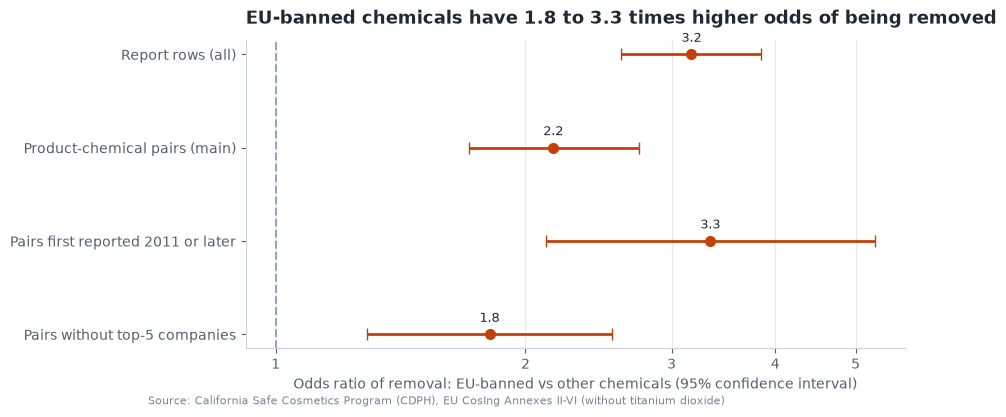

In [5]:
ACCENT, GREY, INK = "#C2410C", "#9AA5B1", "#1F2933"      # same colours as in the EDA notebook
SRC = "Source: California Safe Cosmetics Program (CDPH), EU CosIng Annexes II-VI (without titanium dioxide)"

labels = ["Report rows (all)", "Product-chemical pairs (main)",
          "Pairs first reported 2011 or later", "Pairs without top-5 companies"]   # same order as the summary table
y = np.arange(len(summary))[::-1]                          # first result on top

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.errorbar(summary["odds_ratio"], y,
            xerr=[summary["odds_ratio"] - summary["ci_low"], summary["ci_high"] - summary["odds_ratio"]],
            fmt="o", color=ACCENT, ecolor=ACCENT, capsize=4, markersize=7, linewidth=2)   # dot = odds ratio, bar = 95% CI
ax.axvline(1, color=GREY, linestyle="--", linewidth=1.5)    # 1 = no difference between banned and not banned
for yi, orr in zip(y, summary["odds_ratio"]):
    ax.annotate(f"{orr:.1f}", (orr, yi), textcoords="offset points", xytext=(0, 9), ha="center", color=INK, fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xscale("log")                                        # odds ratios are ratios, so a log axis is fair
ax.set_xticks([1, 2, 3, 4, 5])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.minorticks_off()
ax.xaxis.grid(True, color="#E4E7EB")
ax.set_axisbelow(True)
ax.set_xlabel("Odds ratio of removal: EU-banned vs other chemicals (95% confidence interval)", color="#52606D")
ax.set_title("EU-banned chemicals have 1.8 to 3.3 times higher odds of being removed", loc="left",
             fontsize=13, fontweight="bold", color=INK, pad=12)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#CBD2D9")
ax.tick_params(colors="#52606D")
fig.text(0.01, -0.03, SRC, fontsize=8, color="#7B8794")
ax.annotate("no difference", (1, y[-1] - 0.45), xytext=(1.03, y[-1] - 0.45), color="#52606D", fontsize=9)   # label next to the dashed line
fig.savefig("../images/10_h1_odds_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

## Findings: H1

- **Result:** I reject H0. EU-banned chemicals were removed significantly more often than other chemicals (chi-square test, p < 0.001 in all versions).
- **Size:** 16.7% vs 5.9% of the report rows, and 17.5% vs 9.0% of the product-chemical pairs. The odds of removal are 2.2 times higher (95% CI 1.7 to 2.7) in the main analysis (pairs).
- **Robustness:** the result holds when the initial reporting wave (2009-2010) is excluded (odds ratio 3.3) and when the five companies with the most banned entries are excluded (odds ratio 1.8).
- **Effect size:** Cramér's V is 0.05 to 0.10, which is a small effect. The association is clear but modest.
- **Limits:** this is an association, not proof that the EU rules caused the removals. Product category, company and other factors are not controlled. TiO2 and rows without CAS are excluded.

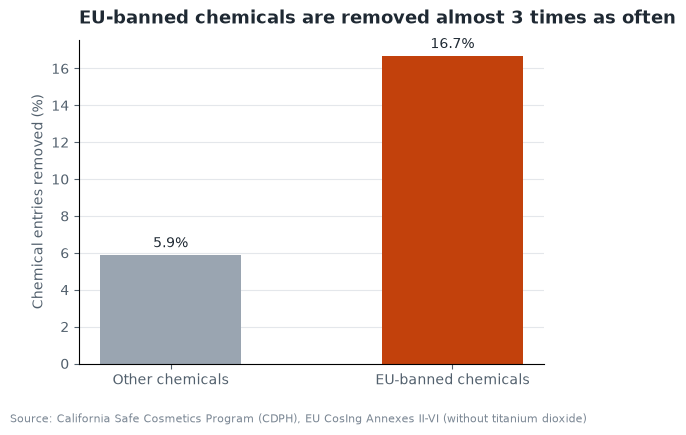

In [6]:
# two bars with the H1 numbers: share of removed chemical entries, banned vs other (no TiO2, known CAS)
share_rows = t1["removed %"]                              # from Table 1: not banned = 5.9, banned = 16.7
fig, ax = plt.subplots(figsize=(6, 4.2))
bars = ax.bar(["Other chemicals", "EU-banned chemicals"], [share_rows["not banned"], share_rows["banned"]],
              width=0.5, color=[GREY, ACCENT])
ax.bar_label(bars, fmt="%.1f%%", padding=3, color=INK)
ax.yaxis.grid(True, color="#E4E7EB")
ax.set_axisbelow(True)
ax.set_ylabel("Chemical entries removed (%)", color="#52606D")
ax.set_title("EU-banned chemicals are removed almost 3 times as often", loc="left", fontsize=13,
             fontweight="bold", color=INK, pad=12)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors="#52606D")
fig.text(0.01, -0.03, SRC, fontsize=8, color="#7B8794")
fig.savefig("../images/11_h1_removal_share.png", dpi=200, bbox_inches="tight")
plt.show()

## H4: 
- Do big companies remove EU-banned chemicals more often than small ones?
- **H0:** Among EU-banned product-chemical pairs, the share removed is the same for big and small companies.
- **H4:** The shares differ.
- **Company size:** number of reported products per company (a proxy; there is no revenue in the data). Big = the top 10% of companies by product count, small = all others.
- **Test:** chi-square test and Fisher’s exact test (the groups are small), α = 0.05, plus the odds ratio.

In [7]:
# 1. Company size = number of reported products per company; "big" = top 10% of companies
size = q("SELECT company_id, COUNT(*) AS n_products FROM products GROUP BY company_id")
cut = size["n_products"].quantile(0.90)                           # threshold: 90th percentile of product counts
size["big"] = (size["n_products"] >= cut).astype(int)             # 1 = big, 0 = small
print(f"threshold: {cut:.0f} products | big companies: {size['big'].sum()} of {len(size)}")

# 2. Add the size group to the pair-level data from the robustness checks (no TiO2, known CAS)
d = pairs2.merge(size[["company_id", "big"]], on="company_id")

# 3. Descriptive: how many of each group's pairs involve an EU-banned chemical?
print("\nShare of pairs with an EU-banned chemical:")
print((100 * d.groupby("big")["eu_banned"].mean()).round(1).rename({0: "small", 1: "big"}))

# 4. H4 test: only EU-banned pairs; is the removal share different for big and small companies?
db = d[d["eu_banned"] == 1]
t4 = pd.crosstab(db["big"], db["is_removed"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
t4.index = ["small", "big"]
t4.columns = ["kept", "removed"]
t4["removed %"] = (100 * t4["removed"] / (t4["kept"] + t4["removed"])).round(1)
print("\nBanned pairs by company size:")
print(t4)

res4 = h1_test(t4, "H4: big vs small companies (banned pairs)")       # same test function; 'banned' row = big here
odds, p_fisher = stats.fisher_exact(t4[["kept", "removed"]].values)   # exact test, better for small counts
print(f"Fisher exact: odds ratio = {odds:.2f}, p = {p_fisher:.3f}")

threshold: 136 products | big companies: 64 of 635

Share of pairs with an EU-banned chemical:
big
small    13.7
big       3.8
Name: eu_banned, dtype: float64

Banned pairs by company size:
       kept  removed  removed %
small   373       70       15.8
big      88       28       24.1
--- H4: big vs small companies (banned pairs) ---
chi-square = 4.4, df = 1, p = 3.55e-02
smallest expected count = 20  (must be at least 5)
difference = 8.3 percentage points
odds ratio = 1.70  (95% CI 1.03 to 2.78)
Cramer's V = 0.089
Fisher exact: odds ratio = 1.70, p = 0.040


In [8]:
# Does the H4 result depend on where we draw the line between "big" and "small"?
rows = []
for quant in [0.75, 0.80, 0.90, 0.95]:                                  # different definitions of "big"
    cut = size["n_products"].quantile(quant)
    big = (size.set_index("company_id")["n_products"] >= cut).astype(int)   # 1 = big
    dd = pairs2[pairs2["eu_banned"] == 1].copy()                        # only EU-banned pairs
    dd["big"] = dd["company_id"].map(big)
    t = pd.crosstab(dd["big"], dd["is_removed"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    odds, p = stats.fisher_exact(t.values)                              # exact test
    rows.append({"top share": f"{round((1 - quant) * 100)}%", "threshold": int(cut),
                 "removed % small": round(100 * t.loc[0, 1] / t.loc[0].sum(), 1),
                 "removed % big": round(100 * t.loc[1, 1] / t.loc[1].sum(), 1),
                 "odds ratio": round(odds, 2), "p (Fisher)": round(p, 3)})
print(pd.DataFrame(rows).to_string(index=False))

top share  threshold  removed % small  removed % big  odds ratio  p (Fisher)
      25%         35             17.9           17.0        0.94       0.823
      20%         53             16.8           18.7        1.14       0.570
      10%        136             15.8           24.1        1.70       0.040
       5%        269             16.1           24.0        1.64       0.080


## Findings: H4 (exploratory): inconclusive

- **Exposure:** big companies (top 10% by product count) have EU-banned chemicals in 3.8% of their product-chemical pairs, small companies in 13.7% (descriptive, not tested).
- **Removal:** with "big" defined as the top 10%, big companies removed banned chemicals more often (24.1% vs 15.8%; odds ratio 1.7; Fisher p = 0.040).
- **Sensitivity:** the result is not stable. With other definitions of "big" the odds ratio is 0.94 (top 25%, p = 0.82), 1.14 (top 20%, p = 0.57) and 1.64 (top 5%, p = 0.08). Only one of four definitions is significant.
- **Conclusion:** no reliable evidence that company size affects the removal of EU-banned chemicals. I report this as an exploratory, inconclusive result and keep H1 as the main finding.
- **Limits:** company size = number of reported products (not revenue); several tests were run, so a single borderline p-value is not trusted.